# EV Charging Station Energy Demand & Dynamic Pricing Optimization

 Problem Statement
With the rapid global shift toward electric vehicles (EVs),
power grids and charging network operators face severe strain during peak hours.
Unpredictable charging spikes lead to grid instability, transformer overloads,
and volatile electricity pricing for consumers.

Target Variable: Total Energy Consumption per Charging Session (kWh) or 
Aggregated Station Load (kW) at 15-minute intervals.

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Loading Dataset

In [2]:
df = pd.read_csv("global_ev_charging_station.csv")

Displaying the first few rows to verify it loaded successfully

In [3]:
df.head()

,StationID,UUID,DataProviderID,Operator,UsageType,UsageCost,AddressTitle,AddressLine1,Town,StateOrProvince,Postcode,Country,Latitude,Longitude,MaxPowerKW,FastChargeCount,ConnectionTypes,StatusType,YearCreated
0,473101,5B1E6265-45A9-4D0E-83A7-AB49D84D0BB2,1,Tesla (including non-tesla),Public,NaN,Tesla Supercharger,Purley Way,NaN,NaN,NaN,United Kingdom,51.371709,-0.116955,250.0,1,CCS (Type 2),Operational,2026
1,472908,A5EA67A8-756B-4C09-B578-BAEC40AEA237,1,Lidl,Public - Membership Required,£0.57/kWh,Positive Energy - DoubleTree by Hilton Manches...,Outwood Road,Wythenshawe,England,M90 4HL,United Kingdom,53.366453,-2.269799,11.0,0,Type 2 (Socket Only),Operational,2026
2,472220,1CCABB37-2CE5-49D4-8DC0-5025BE976BA1,1,EZO (IE),Public - Membership Required,NaN,Holiday Inn Express,106 University Street,Belfast,NaN,BT7 1HP,United Kingdom,54.586836,-5.926869,50.0,1,CCS (Type 2),Operational,2025
3,471954,0E7B7267-6DEE-4E85-91F4-D11B8FF789A9,1,BMM Energy (UK),Public - Membership Required,NaN,South Tyrone Hospital,Carland Road,Dungannon,NaN,BT71 4AU,United Kingdom,54.509453,-6.768057,22.0,0,Type 2 (Socket Only),Operational,2025
4,471953,A4E4A241-BF88-4394-99B2-B0B788FE3287,1,BMM Energy (UK),Public - Membership Required,NaN,Armagh Community Hospital,Victoria Grove,Armagh,NaN,BT61 9DH,United Kingdom,54.350644,-6.641787,22.0,0,Type 2 (Socket Only),Operational,2025


Checking all available column

In [4]:
df.columns

Index(['StationID', 'UUID', 'DataProviderID', 'Operator', 'UsageType',
       'UsageCost', 'AddressTitle', 'AddressLine1', 'Town', 'StateOrProvince',
       'Postcode', 'Country', 'Latitude', 'Longitude', 'MaxPowerKW',
       'FastChargeCount', 'ConnectionTypes', 'StatusType', 'YearCreated'],
      dtype='object')

Checking data types and non-null counts

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257585 entries, 0 to 257584
Data columns (total 19 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   StationID        257585 non-null  int64  
 1   UUID             257585 non-null  object 
 2   DataProviderID   257585 non-null  int64  
 3   Operator         218360 non-null  object 
 4   UsageType        222469 non-null  object 
 5   UsageCost        61828 non-null   object 
 6   AddressTitle     257580 non-null  object 
 7   AddressLine1     255768 non-null  object 
 8   Town             234832 non-null  object 
 9   StateOrProvince  182833 non-null  object 
 10  Postcode         230510 non-null  object 
 11  Country          257585 non-null  object 
 12  Latitude         257585 non-null  float64
 13  Longitude        257585 non-null  float64
 14  MaxPowerKW       257585 non-null  float64
 15  FastChargeCount  257585 non-null  int64  
 16  ConnectionTypes  252709 non-null  obje

Stastical summary

In [6]:
df.describe()

,StationID,DataProviderID,Latitude,Longitude,MaxPowerKW,FastChargeCount,YearCreated
count,257585.000000,257585.000000,257585.000000,257585.000000,257585.000000,257585.000000,257585.000000
mean,214027.344244,6.300320,43.024583,-32.331054,36.094556,0.453113,2021.177984
std,112354.931522,9.758291,13.060504,57.567388,1971.171374,1.047234,3.404048
min,2389.000000,1.000000,-55.811599,-164.848855,0.000000,0.000000,2010.000000
25%,127474.000000,1.000000,38.785981,-81.528641,3.700000,0.000000,2019.000000
50%,213775.000000,2.000000,44.293968,-3.117260,11.000000,0.000000,2023.000000
75%,289084.000000,2.000000,51.343085,7.690003,22.000000,0.000000,2024.000000
max,474214.000000,45.000000,81.736061,178.369254,1000000.000000,46.000000,2026.000000


Check missing values

In [7]:
df.isnull().sum()

StationID               0
UUID                    0
DataProviderID          0
Operator            39225
UsageType           35116
UsageCost          195757
AddressTitle            5
AddressLine1         1817
Town                22753
StateOrProvince     74752
Postcode            27075
Country                 0
Latitude                0
Longitude               0
MaxPowerKW              0
FastChargeCount         0
ConnectionTypes      4876
StatusType          36392
YearCreated             0
dtype: int64

Checking duplicate records

In [8]:
df.duplicated().sum()

3

# Data Preprocessing & Feature Selection

Dropping rows where our target or key numeric features are missing

In [9]:
df_clean = df.dropna(subset=['MaxPowerKW', 'Latitude', 'Longitude', 'FastChargeCount', 'YearCreated']).copy()

Defining our Independent Features (X) and Target Variable (Y)

In [10]:
X = df_clean[['Latitude', 'Longitude', 'FastChargeCount', 'YearCreated']]
y = df_clean['MaxPowerKW']

Check the shape of our prepared data

In [11]:
print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

Features shape (X): (257585, 4)
Target shape (y): (257585,)


# Splitting the Data & Training Linear Regression Model!

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

Splitting the data into 80% Training and 20% Testing sets

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Initializing the Multiple Linear Regression model

In [14]:
model = LinearRegression()

Train (fit) the model using the training data


In [15]:
model.fit(X_train, y_train)
print("Model training completed successfully!")
print("Intercept (b0):", model.intercept_)
print("Coefficients (b1, b2, ...):", model.coef_)

Model training completed successfully!
Intercept (b0): -7489.647676529181
Coefficients (b1, b2, ...): [-0.89232356  0.30438242 29.78295494  3.74106569]


# Model Evaluation.

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Making predictions on our test set

In [17]:
y_pred = model.predict(X_test)

Calculating evaluation metrics

In [18]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False) # or np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

In [19]:
print("--- Model Performance Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

--- Model Performance Metrics ---
Mean Absolute Error (MAE): 28.25
Root Mean Squared Error (RMSE): 52.81
R-squared (R2) Score: 0.2284


# Model Interpretation & Improvement

Creating a DataFrame to view feature coefficients side by side

In [20]:
coefficients_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_})
print(coefficients_df)
print("\nIntercept (Base Power):", model.intercept_)

           Feature  Coefficient
0         Latitude    -0.892324
1        Longitude     0.304382
2  FastChargeCount    29.782955
3      YearCreated     3.741066

Intercept (Base Power): -7489.647676529181


Visualizing Actual vs. Predicted Values

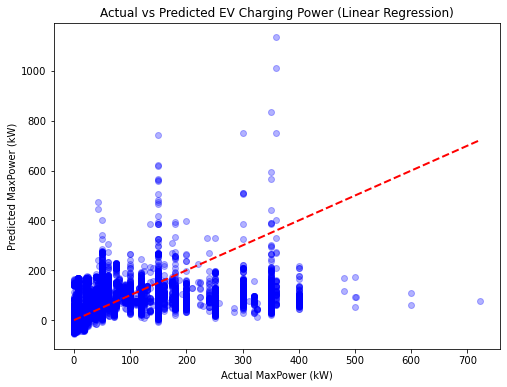

In [21]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', lw=2)
plt.xlabel("Actual MaxPower (kW)")
plt.ylabel("Predicted MaxPower (kW)")
plt.title("Actual vs Predicted EV Charging Power (Linear Regression)")
plt.show()